# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

The passenger series and fares below are the assignment's supplied values: Ntinda is the stated example and Entebbe/Mukono are illustrative. Passenger counts are treated as total one-way passenger trips per route per day. Reusable route, forecasting, equilibrium and fleet-planning logic lives in `src/taxi.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.taxi import (
    ExponentialSmoothingForecaster,
    LinearTrendForecaster,
    MovingAverageForecaster,
    Route,
    SeasonalNaiveForecaster,
    generate_weekly_passenger_counts,
    plan_fleet,
    solve_supply_demand_equilibrium,
    tune_exponential_smoothing_alpha,
)

## Routes, revenues and descriptive statistics

The sample variance and standard deviation are calculated with Python's `statistics` module; variance is in passenger-count-squared units. Revenue calculations multiply passengers by the fixed route fare.

In [2]:
route_inputs = {
    "Kampala-Ntinda": ([35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2_000),
    "Kampala-Entebbe": ([60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5_000),
    "Kampala-Mukono": ([45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3_000),
}
routes = {
    name: Route(name, np.asarray(passengers, dtype=float), fare)
    for name, (passengers, fare) in route_inputs.items()
}
route_summary = pd.DataFrame.from_dict(
    {
        name: {
            "Fare (UGX)": route.fare_ugx,
            "Mean passengers/day": route.descriptive_statistics()["mean"],
            "Passenger variance": route.descriptive_statistics()["variance"],
            "Passenger standard deviation": route.descriptive_statistics()["standard_deviation"],
            "Total 10-day revenue (UGX)": route.total_revenue(),
        }
        for name, route in routes.items()
    },
    orient="index",
)
display(route_summary.round(2))

,Fare (UGX),Mean passengers/day,Passenger variance,Passenger standard deviation,Total 10-day revenue (UGX)
Kampala-Ntinda,2000.0,47.4,54.27,7.37,948000.0
Kampala-Entebbe,5000.0,67.8,45.07,6.71,3390000.0
Kampala-Mukono,3000.0,52.0,26.44,5.14,1560000.0


## Ntinda supply-demand equilibrium

Set `Qd = Qs`: `120 − 0.02P = 10 + 0.03P`. As a 2×2 linear system the equations are `Q + 0.02P = 120` and `Q − 0.03P = 10`, solved with `scipy.linalg.solve`. The model's quantity is passengers per trip-hour and price is UGX; it is a simplified linear illustration, not an estimated market curve.

In [3]:
equilibrium = solve_supply_demand_equilibrium(current_fare_ugx=routes["Kampala-Ntinda"].fare_ugx)
display(pd.Series(equilibrium, name="Ntinda equilibrium"))
print(
    f"The current UGX {equilibrium['current_fare_ugx']:,.0f} fare is "
    f"{equilibrium['current_fare_relation']} the model equilibrium fare of "
    f"UGX {equilibrium['equilibrium_fare_ugx']:,.0f}."
)

quantity_passengers_per_trip_hour      76.0
equilibrium_fare_ugx                 2200.0
current_fare_ugx                     2000.0
current_fare_relation                 below
Name: Ntinda equilibrium, dtype: object

The current UGX 2,000 fare is below the model equilibrium fare of UGX 2,200.


## Forecasters and rolling-origin backtest (days 4–10)

At each test day, a model is fit only on earlier days. For day 4, three training observations are not enough for a nested alpha grid search, so SES uses the predeclared default α = 0.3. From day 5 onward, alpha is selected afresh by grid search over prior history only, avoiding use of the current or future test observation. Day-11 alpha is tuned on all ten observations using rolling-origin validation. Selection uses the smallest passenger-count MAE; fixed fares scale passenger MAE directly into revenue MAE.

In [4]:
alpha_grid = np.arange(0.1, 1.01, 0.1)
mae_rows = []
selected_model_names = {}
day11_forecasts = {}
day11_alphas = {}

for route_name, route in routes.items():
    values = route.passenger_counts
    predictions = {"3-day moving average": [], "Simple exponential smoothing": [], "Linear trend": []}
    actuals = []

    for target_index in range(3, len(values)):
        history = values[:target_index]
        actuals.append(values[target_index])
        predictions["3-day moving average"].append(
            MovingAverageForecaster().fit(history).predict()[0]
        )
        alpha = (
            0.3 if len(history) == 3
            else tune_exponential_smoothing_alpha(history, alphas=alpha_grid, initial_training_size=3)[0]
        )
        predictions["Simple exponential smoothing"].append(
            ExponentialSmoothingForecaster(alpha).fit(history).predict()[0]
        )
        predictions["Linear trend"].append(
            LinearTrendForecaster().fit(history).predict()[0]
        )

    for model_name, model_predictions in predictions.items():
        mae_rows.append({
            "Route": route_name,
            "Model": model_name,
            "Walk-forward MAE (passengers)": float(np.mean(np.abs(np.asarray(model_predictions) - actuals))),
            "Walk-forward MAE (revenue UGX)": float(np.mean(np.abs(np.asarray(model_predictions) - actuals)) * route.fare_ugx),
        })

    route_mae = [row for row in mae_rows if row["Route"] == route_name]
    best_row = min(route_mae, key=lambda row: row["Walk-forward MAE (passengers)"])
    selected_model_names[route_name] = best_row["Model"]
    day11_alpha, _ = tune_exponential_smoothing_alpha(
        values, alphas=alpha_grid, initial_training_size=3
    )
    day11_alphas[route_name] = day11_alpha
    day11_model = {
        "3-day moving average": MovingAverageForecaster(),
        "Simple exponential smoothing": ExponentialSmoothingForecaster(day11_alpha),
        "Linear trend": LinearTrendForecaster(),
    }[best_row["Model"]]
    predicted_passengers = float(day11_model.fit(values).predict()[0])
    day11_forecasts[route_name] = {
        "passengers": predicted_passengers,
        "revenue_ugx": predicted_passengers * route.fare_ugx,
    }

mae_table = pd.DataFrame(mae_rows)
display(mae_table.pivot(index="Route", columns="Model", values="Walk-forward MAE (passengers)").round(2))
print("Chosen model by route:", selected_model_names)
print("Full-history tuned alpha for SES routes:", day11_alphas)

Model,3-day moving average,Linear trend,Simple exponential smoothing
Route,,,
Kampala-Entebbe,7.19,7.71,4.99
Kampala-Mukono,5.33,6.39,4.48
Kampala-Ntinda,7.52,7.87,6.43


Chosen model by route: {'Kampala-Ntinda': 'Simple exponential smoothing', 'Kampala-Entebbe': 'Simple exponential smoothing', 'Kampala-Mukono': 'Simple exponential smoothing'}
Full-history tuned alpha for SES routes: {'Kampala-Ntinda': 1.0, 'Kampala-Entebbe': 1.0, 'Kampala-Mukono': 1.0}


## Day-11 revenue forecast and buffered fleet planning

Each vehicle supplies `8 × 14 = 112` one-way seat-trips per day. The fleet calculation treats each passenger observation as one passenger trip and applies the 15% buffer to forecast demand before rounding vehicle counts up. Actual load factors, round trips, route distance, crew schedules and vehicle availability are not modeled.

In [5]:
planning_rows = []
for route_name, route in routes.items():
    forecast = day11_forecasts[route_name]
    fleet = plan_fleet(forecast["passengers"], trips_per_vehicle_per_day=8, seats_per_vehicle=14, buffer_fraction=0.15)
    planning_rows.append({
        "Route": route_name,
        "Selected model": selected_model_names[route_name],
        "Day-11 passengers": forecast["passengers"],
        "Day-11 revenue (UGX)": forecast["revenue_ugx"],
        "Demand with 15% buffer": fleet["buffered_passengers"],
        "Vehicle daily capacity": fleet["one_vehicle_daily_capacity"],
        "Vehicles to deploy": fleet["vehicles"],
    })
planning_table = pd.DataFrame(planning_rows).set_index("Route")
display(planning_table.round(2))

,Selected model,Day-11 passengers,Day-11 revenue (UGX),Demand with 15% buffer,Vehicle daily capacity,Vehicles to deploy
Route,,,,,,
Kampala-Ntinda,Simple exponential smoothing,45.0,90000.0,51.75,112,1
Kampala-Entebbe,Simple exponential smoothing,64.0,320000.0,73.60,112,1
Kampala-Mukono,Simple exponential smoothing,50.0,150000.0,57.50,112,1


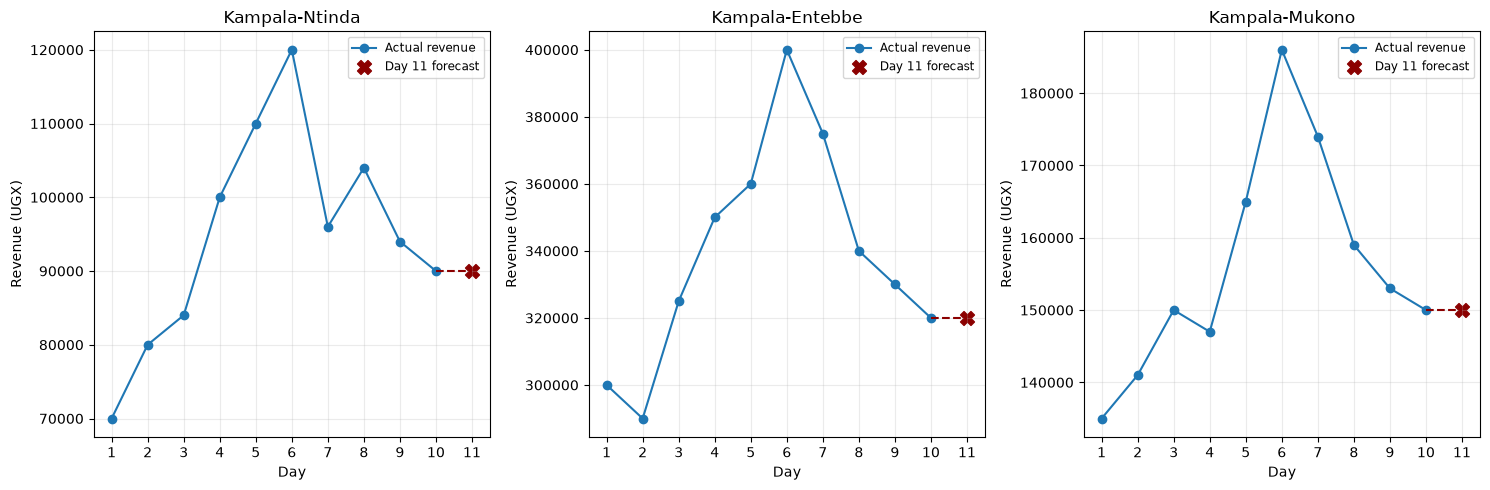

In [6]:
fig, axes = plt.subplots(1, len(routes), figsize=(15, 5), sharey=False)
for ax, (route_name, route) in zip(axes, routes.items()):
    actual_revenue = route.daily_revenue()
    day11_revenue = day11_forecasts[route_name]["revenue_ugx"]
    days = np.arange(1, len(actual_revenue) + 1)
    ax.plot(days, actual_revenue, marker="o", label="Actual revenue")
    ax.scatter([11], [day11_revenue], marker="X", s=100, color="darkred", label="Day 11 forecast")
    ax.plot([10, 11], [actual_revenue[-1], day11_revenue], linestyle="--", color="darkred")
    ax.set(title=route_name, xlabel="Day", ylabel="Revenue (UGX)")
    ax.set_xticks(range(1, 12))
    ax.grid(alpha=0.25)
    ax.legend(fontsize="small")
fig.tight_layout()
plt.show()

## Extension: 60-day weekly seasonality

The seeded synthetic series includes higher Friday and lower Sunday demand. Walk-forward evaluation starts on day 8 so a full seven-day seasonal cycle is available. Both models predict the next day from the same history; the seasonal-naive method copies the count from seven days earlier.

,MAE (passengers)
Model,
3-day moving average,7.89
7-day seasonal naive,3.02


Weekly weekday means (Mon=0, ..., Sun=6): [50.6, 48.7, 50.5, 53.6, 67.9, 56.1, 36.6]


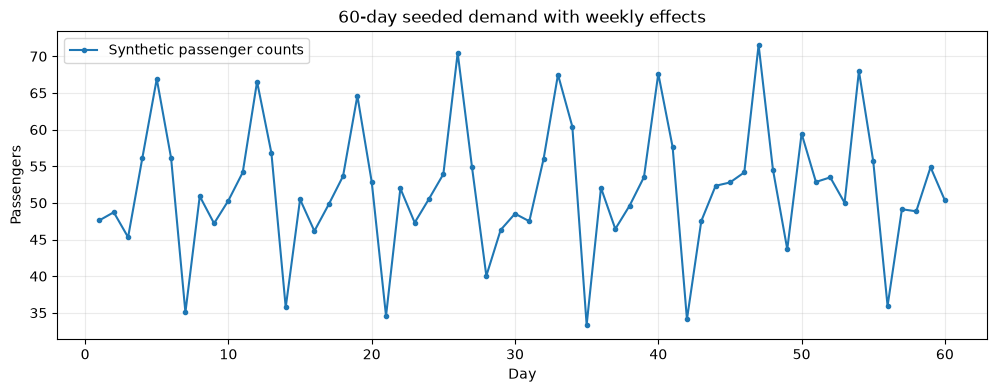

In [7]:
seasonal_counts = generate_weekly_passenger_counts(days=60, seed=2026)
seasonal_mae_rows = []
seasonal_predictions = {"3-day moving average": [], "7-day seasonal naive": []}
seasonal_actuals = []
for target_index in range(7, len(seasonal_counts)):
    history = seasonal_counts[:target_index]
    seasonal_actuals.append(seasonal_counts[target_index])
    seasonal_predictions["3-day moving average"].append(MovingAverageForecaster().fit(history).predict()[0])
    seasonal_predictions["7-day seasonal naive"].append(SeasonalNaiveForecaster().fit(history).predict()[0])
for model_name, predictions in seasonal_predictions.items():
    seasonal_mae_rows.append({
        "Model": model_name,
        "MAE (passengers)": float(np.mean(np.abs(np.asarray(predictions) - seasonal_actuals))),
    })
seasonal_mae_table = pd.DataFrame(seasonal_mae_rows).set_index("Model")
display(seasonal_mae_table.round(2))
assert seasonal_mae_table.loc["7-day seasonal naive", "MAE (passengers)"] < seasonal_mae_table.loc["3-day moving average", "MAE (passengers)"]
print("Weekly weekday means (Mon=0, ..., Sun=6):", [round(float(np.mean(seasonal_counts[day::7])), 1) for day in range(7)])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(np.arange(1, 61), seasonal_counts, marker=".", label="Synthetic passenger counts")
ax.set(title="60-day seeded demand with weekly effects", xlabel="Day", ylabel="Passengers")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Findings & Limitations

The stated linear curves intersect at UGX 2,200 and 76 passengers per trip-hour, putting the current Ntinda fare of UGX 2,000 below this model equilibrium. This is an algebraic result from assumed curves, not an empirical fare recommendation. Route backtests use seven one-day-ahead rolling predictions (days 4–10), fitting on prior observations only; exponential-smoothing alpha is tuned within each available history to avoid leakage. The winning model can vary by route, and ten observations are too few to establish stable route-level dynamics. Since fares are fixed, passenger-count MAE translates directly to revenue MAE by multiplying by fare.

The 15% buffered demand is converted into whole vehicles with a capacity of 112 one-way seat-trips per vehicle-day. This assumes every predicted passenger is a separate one-way trip, full seats are available on all trips, and vehicles can complete eight trips; real load factors, peak-hour imbalance, deadheading, trip length, maintenance, staffing, accessibility and safety reserves could materially change fleet need. The extension uses seeded synthetic weekday effects to demonstrate seasonal-naive forecasting; its advantage over a short moving average is specific to this generated pattern and is not evidence that real route demand follows the same cycle. Actual deployment decisions need longer route-specific ticketing data and operational constraints.

## References

- Course assignment prompt for the passenger series, fares, demand and supply curves, vehicle capacity assumptions and project requirements.
- SciPy documentation: [`scipy.linalg.solve`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve.html).
- Python documentation: [`statistics`](https://docs.python.org/3/library/statistics.html).
- NumPy documentation: [`numpy.polyfit`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html) and [`numpy.random.default_rng`](https://numpy.org/doc/stable/reference/random/generator.html).
- The added 60-day passenger series is synthetic and reproducible from the notebook's fixed seed; it is not observed route data.